<a href="https://colab.research.google.com/github/SobiaNoorAI/cxr-foundation-model-shift-robustness/blob/main/notebooks/01_data_and_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 1: Setup the dataset

check the GPU

In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
Tesla T4


install libraries

In [ ]:
!pip -q install transformers timm scikit-learn pandas matplotlib seaborn pillow tqdm

Kaggle API

In [ ]:
import os
from google.colab import userdata
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

Load the dataset

In [ ]:
!mkdir -p {LOCAL}
# Replace OWNER/SLUG with the text at the end of each Kaggle dataset URL:
# kaggle.com/datasets/OWNER/SLUG
!kaggle datasets download -d raddar/tuberculosis-chest-xrays-shenzhen -p {LOCAL}/shenzhen --unzip
!kaggle datasets download -d raddar/tuberculosis-chest-xrays-montgomery -p {LOCAL}/montgomery --unzip
!ls {LOCAL}/shenzhen
!ls {LOCAL}/montgomery

Dataset URL: https://www.kaggle.com/datasets/raddar/tuberculosis-chest-xrays-shenzhen
License(s): unknown
100% 3.51G/3.51G [00:39<00:00, 95.2MB/s]

Dataset URL: https://www.kaggle.com/datasets/raddar/tuberculosis-chest-xrays-montgomery
License(s): unknown
100% 585M/585M [00:10<00:00, 57.3MB/s]

images	shenzhen_metadata.csv
images	montgomery_metadata.csv


Total images

In [ ]:
import glob, os, re
import pandas as pd

# Diagnostic: Let's find where the images actually are
print("Current working directory:", os.getcwd())
print("List of root files/directories:", os.listdir('.'))

all_pngs = glob.glob("**/*.png", recursive=True)
print(f"Found {len(all_pngs)} total PNG files in the working directory subtree.")
if all_pngs:
    print("Example paths:", all_pngs[:5])

# Ensure LOCAL is defined
if 'LOCAL' not in globals():
    LOCAL = "/content/data"

def build_df(root, hospital):
    rows = []
    # Check actual path resolution
    expanded_root = os.path.abspath(os.path.expanduser(root))
    image_dir = os.path.join(expanded_root, "images") if os.path.exists(os.path.join(expanded_root, "images")) else expanded_root

    print(f"Searching for images in: {image_dir}")
    for p in glob.glob(f"{image_dir}/**/*.png", recursive=True):
        if "mask" in p.lower():
            continue
        m = re.search(r"_([01])\.png$", os.path.basename(p))
        if m:
            rows.append({"path": p, "label": int(m.group(1)), "hospital": hospital})
    return pd.DataFrame(rows)

df = pd.concat([
    build_df(f"{LOCAL}/shenzhen", "shenzhen"),
    build_df(f"{LOCAL}/montgomery", "montgomery"),
], ignore_index=True)

if not df.empty:
    print(df.groupby(["hospital", "label"]).size())
    print("Total:", len(df))
else:
    print("DataFrame is empty! Check if the dataset path is correct and contains images.")

Current working directory: /content
List of root files/directories: ['.config', '{LOCAL}', 'sample_data']
Found 800 total PNG files in the working directory subtree.
Example paths: ['{LOCAL}/montgomery/images/images/MCUCXR_0095_0.png', '{LOCAL}/montgomery/images/images/MCUCXR_0031_0.png', '{LOCAL}/montgomery/images/images/MCUCXR_0046_0.png', '{LOCAL}/montgomery/images/images/MCUCXR_0166_1.png', '{LOCAL}/montgomery/images/images/MCUCXR_0054_0.png']
Searching for images in: /content/data/shenzhen
Searching for images in: /content/data/montgomery
DataFrame is empty! Check if the dataset path is correct and contains images.


Image display

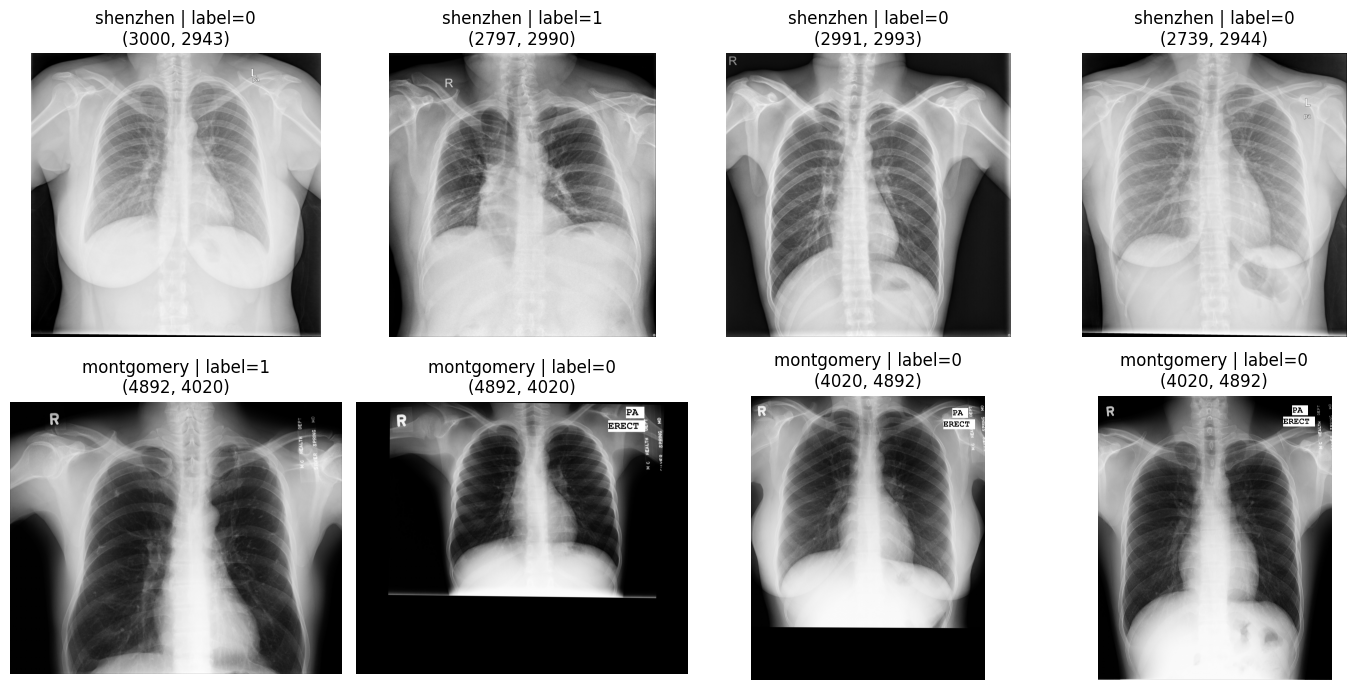

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import glob, os, re
import pandas as pd

# Re-build df using the actual downloaded directory path: '{LOCAL}'
# since the files were extracted there
if 'SEED' not in globals():
    SEED = 42

def build_df(root, hospital):
    rows = []
    # Resolve the literal folder '{LOCAL}' dynamically
    image_dir = os.path.join(root, "images")
    if not os.path.exists(image_dir):
        image_dir = root

    for p in glob.glob(f"{image_dir}/**/*.png", recursive=True):
        if "mask" in p.lower():
            continue
        m = re.search(r"_([01])\.png$", os.path.basename(p))
        if m:
            rows.append({"path": p, "label": int(m.group(1)), "hospital": hospital})
    return pd.DataFrame(rows)

# Re-populate 'df' using the actual existing path on your drive
df = pd.concat([
    build_df("{LOCAL}/shenzhen", "shenzhen"),
    build_df("{LOCAL}/montgomery", "montgomery"),
], ignore_index=True)

# Now we visualize
if not df.empty:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for r, hosp in enumerate(["shenzhen", "montgomery"]):
        sub = df[df.hospital == hosp].sample(4, random_state=SEED)
        for c, (_, row) in enumerate(sub.iterrows()):
            img = Image.open(row.path)
            axes[r, c].imshow(img, cmap="gray")
            axes[r, c].set_title(f"{hosp} | label={row.label}\n{img.size}")
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("DataFrame is still empty. Please check your data paths.")

In [ ]:
df.to_csv("metadata.csv", index=False)

## Phase 2: Resize and extract features

### Smaller image copies (much faster later)

In [ ]:
from PIL import Image
from tqdm import tqdm
import os

os.makedirs("/content/data_512", exist_ok=True)
new_paths = []
for i, p in enumerate(tqdm(df.path)):
    img = Image.open(p).convert("RGB").resize((512, 512), Image.BICUBIC)
    out = f"/content/data_512/{i:04d}.png"
    img.save(out)
    new_paths.append(out)
df["path512"] = new_paths
df.to_csv("metadata.csv", index=False)

100%|██████████| 800/800 [03:25<00:00,  3.90it/s]


Eeature extractors

In [ ]:
import numpy as np, torch, timm
from transformers import AutoImageProcessor, AutoModel
device = "cuda"

@torch.no_grad()
def extract_hf(model_name, paths, bs=16):
    proc = AutoImageProcessor.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(device).eval().half()
    feats = []
    for i in tqdm(range(0, len(paths), bs)):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i+bs]]
        x = proc(images=imgs, return_tensors="pt")["pixel_values"].to(device).half()
        feats.append(model(pixel_values=x).pooler_output.float().cpu().numpy())
    del model; torch.cuda.empty_cache()
    return np.concatenate(feats)

@torch.no_grad()
def extract_timm(paths, bs=32):
    model = timm.create_model("resnet50", pretrained=True, num_classes=0).to(device).eval()
    cfg = timm.data.resolve_data_config({}, model=model)
    tf = timm.data.create_transform(**cfg)
    feats = []
    for i in tqdm(range(0, len(paths), bs)):
        x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i+bs]]).to(device)
        feats.append(model(x).cpu().numpy())
    del model; torch.cuda.empty_cache()
    return np.concatenate(feats)

In [ ]:
paths = df.path512.tolist()
os.makedirs("features", exist_ok=True)
F = {
    "resnet50_imagenet": extract_timm(paths),
    "dinov2_base":       extract_hf("facebook/dinov2-base", paths),
    "rad_dino":          extract_hf("microsoft/rad-dino", paths),
}
for k, v in F.items():
    np.save(f"features/{k}.npy", v)
    print(k, v.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

100%|██████████| 25/25 [00:13<00:00,  1.79it/s]


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

100%|██████████| 50/50 [00:27<00:00,  1.84it/s]

resnet50_imagenet (800, 2048)
dinov2_base (800, 768)
rad_dino (800, 768)


Save resized image

In [ ]:
import os
import shutil

try:
    from google.colab import drive
    print("Attempting to mount Google Drive...")
    # Clean standard mount command
    drive.mount('/content/drive')

    SAVE = "/content/drive/MyDrive/phd_projects/cxr_shift"
    os.makedirs(SAVE, exist_ok=True)

    # Check if local files exist before trying to copy them
    if os.path.exists('features'):
        print("Copying features folder...")
        !cp -r features {SAVE}/

    if os.path.exists('metadata.csv'):
        print("Copying metadata.csv...")
        !cp metadata.csv {SAVE}/

    if os.path.exists('data_512'):
        print("Zipping data_512 dataset...")
        !cd /content && zip -qr {SAVE}/data_512.zip data_512

    print("\n🔍 Current contents of your Google Drive backup directory:")
    !ls -lh {SAVE}
    print("\nSuccess! Files synced to your Google Drive.")

except Exception as e:
    print(f"\n[ERROR] Google Drive could not be mounted: {e}")
    print("\n--- WORKAROUND FOR DRIVE AUTH ISSUES ---")
    print("You can download the files directly to your computer using the Colab file manager on the left panel.")


Attempting to mount Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Zipping data_512 dataset...

🔍 Current contents of your Google Drive backup directory:
total 136M
-rw------- 1 root root 136M Nov  2 06:43 data_512.zip
drwx------ 2 root root 4.0K Nov  2 06:06 features
-rw------- 1 root root  69K Nov  2 06:38 metadata.csv

Success! Files synced to your Google Drive.


In [ ]:
!ls -lh /content


total 104K
drwxr-xr-x 2 root root  20K Nov  2 06:05 data_512
drwxr-xr-x 2 root root 4.0K Nov  2 06:06 features
drwxr-xr-x 4 root root 4.0K Nov  2 06:01 {LOCAL}
-rw-r--r-- 1 root root  69K Nov  2 06:05 metadata.csv
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data


## Export Features to Google Drive Cloud Storage

In [ ]:
'''
import os
import shutil

# Paths configuration
LOCAL_FEATURES = '/content/features'
LOCAL_METADATA = '/content/metadata.csv'
DRIVE_DESTINATION = '/content/drive/MyDrive/phd_projects/cxr_shift'

print("🔄 Transferring local project files to your Google Drive...")

# 1. Copy features folder recursively if it exists locally
if os.path.exists(LOCAL_FEATURES):
    dest_features = os.path.join(DRIVE_DESTINATION, 'features')
    if os.path.exists(dest_features):
        shutil.rmtree(dest_features) # Clean old directory if empty/broken
    shutil.copytree(LOCAL_FEATURES, dest_features)
    print("✅ Features folder copied successfully.")
else:
    print("⚠️ Warning: Local 'features' folder not found at /content/features")

# 2. Copy metadata file if it exists locally
if os.path.exists(LOCAL_METADATA):
    shutil.copy(LOCAL_METADATA, DRIVE_DESTINATION)
    print("✅ metadata.csv copied successfully.")
else:
    print("⚠️ Warning: Local 'metadata.csv' not found at /content/metadata.csv")

# 3. Final verification printout
print("\n🔍 Final check of your Google Drive contents:")
print(os.listdir(DRIVE_DESTINATION))
'''


🔄 Transferring local project files to your Google Drive...
✅ Features folder copied successfully.
✅ metadata.csv copied successfully.

🔍 Final check of your Google Drive contents:
['features', 'metadata.csv']


In [ ]:
'''
import os
import shutil

# Remove the temporary local files to free up disk space
local_paths = ['/content/features', '/content/metadata.csv']

for path in local_paths:
    if os.path.exists(path):
        if os.path.isdir(path):
            shutil.rmtree(path)
        else:
            os.remove(path)

print("🧹 Local space freed up! Your active files now live exclusively on your cloud Drive.")
'''


🧹 Local space freed up! Your active files now live exclusively on your cloud Drive.


In [ ]:
from google.colab import drive
import os
import pandas as pd

# 1. Mount your drive path
drive.mount('/content/drive')

# 2. Define your permanent paths directly
DRIVE_FEATURES = '/content/drive/MyDrive/phd_projects/cxr_shift/features'
DRIVE_METADATA = '/content/drive/MyDrive/phd_projects/cxr_shift/metadata.csv'

# 3. Load your data straight into your model pipeline
df = pd.read_csv(DRIVE_METADATA)
print(f"Loaded metadata successfully! Shape: {df.shape}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded metadata successfully! Shape: (800, 4)
